# Самостоятельная работа.

## Стационарное тепловое состояние клапана ДВС

**Осесимметричный метод конечных элементов · Python · Gmsh**

| Параметр | Содержание |
|:--|:--|
| **Формат** | Самостоятельная расчётная работа |
| **Основа** | `geom2bc.ipynb`, `Sem03-PistonHeatTask.ipynb`  и предыдущие семинары| 
| **Результат** | Конечно-элементная модель, температурное поле, проверка теплового баланса и выводы |

**Цель работы.** Самостоятельно подготовить геометрию и сетку клапана, реализовать осесимметричный расчёт стационарной теплопроводности методом конечных элементов и оценить физическую и численную корректность полученного решения.

## 0. Порядок выполнения

Работа состоит из **двух взаимосвязанных частей**:

**Часть I — подготовка конечно-элементной модели в Gmsh:**

1. Открыть CAD-модель клапана и назначить Physical Groups.
2. Построить двумерную сетку линейных треугольников.
3. Получить массивы `pnts`, `elms` и словарь граничных участков `boundary`.
4. Проверить корректность сетки и сохранить данные в текстовых файлах.

**Часть II — расчёт температурного поля:**

5. Задать свойства материала и параметры теплообмена.
6. Реализовать элементные матрицы и сборку глобальной системы.
7. Учесть граничные условия III рода и решить СЛАУ.
8. Построить температурное поле, проверить тепловой баланс и сходимость по сетке.


## 1. Геометрия и граничные условия

### 1.1. Геометрическая модель

В работе используется **меридиональное сечение клапана**, которое при вращении вокруг оси $z$ образует осесимметричное тело. Радиальная координата обозначена $r$, осевая — $z$; **расчётные координаты выражаются в метрах**.

Исходная CAD-геометрия передаётся преподавателем отдельно в формате STEP. (на всякий случай проверьте координаты)


### 1.2. Физические группы (Physical Groups)

В Gmsh требуется выделить поверхности теплообмена как именованные группы кривых. **Границы нельзя объединять только потому, что они геометрически соседствуют:** каждой группе соответствует собственный физический режим.

| Physical Group | Участок | Тип |
|:--|:--|:--:|
| `cc_face` | Поверхность тарелки со стороны камеры сгорания (синий) | Curve |
| `seat_face` | **Короткая** посадочная фаска на периферии тарелки (оранжево-красный) | Curve |
| `channel_face` | Тыльная сторона тарелки и нижняя часть стержня со стороны канала (светло-оранжевый) | Curve |
| `contact_face` | Участок стержня, контактирующий с направляющей втулкой (зелёный) | Curve |
| `top_face` | Верхний торец и небольшой примыкающий участок стержня (светло-зелёный) | Curve |
| `axis` | Ось вращения $r=0$ (голубой) | Curve |
| `valve` | Площадь меридионального сечения материала клапана | Surface |

**Особенно внимательно разметьте `seat_face`:** это только малый участок посадочной фаски вблизи наружного края тарелки, **а не вся её наклонная поверхность**. Основная протяжённая поверхность над тарелкой относится к `channel_face`.

Группа `valve` нужна для экспорта **двумерных треугольников** при наличии физических групп Gmsh. Группа `axis` должна быть определена, но конвекция на ней не задаётся.

<div align="center">

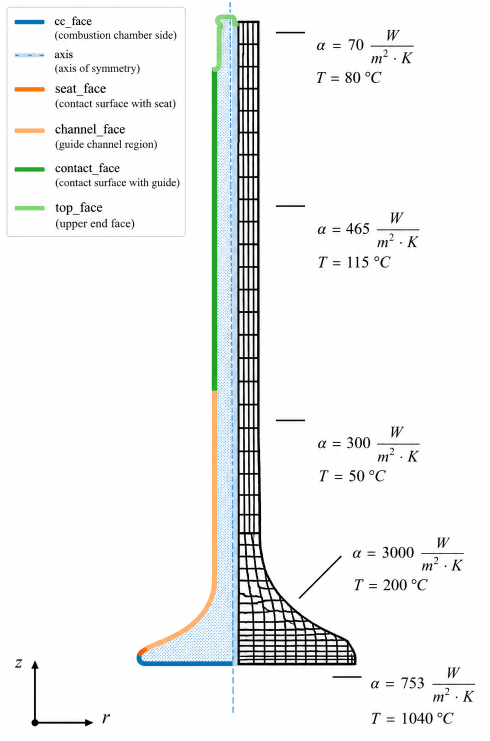

</div>

<p align="center"><em>Рис. 1. Меридиональное сечение клапана, физические группы и параметры теплообмена. Схема адаптирована по примеру из учебника под ред. Н. Д. Чайнова.</em></p>

### 1.3. Исходные параметры теплообмена

Для всех участков, кроме оси, задаются **граничные условия III рода**. Значения в таблице соответствуют **приведённой выше схеме**.

| Группа | $\alpha$, Вт/(м²·К) | $T_\infty$, °C | Физический смысл |
|:--|--:|--:|:--|
| `top_face` | 70 | 80 | Теплообмен верхнего конца стержня |
| `contact_face` | 465 | 115 | Эффективный отвод теплоты в направляющую втулку |
| `channel_face` | 300 | 50 | Теплообмен со средой со стороны канала |
| `seat_face` | 3000 | 200 | Эффективный теплообмен при контакте с седлом |
| `cc_face` | 753 | 1040 | Теплообмен с газами со стороны камеры сгорания |
| `axis` | — | — | Условие осевой симметрии |

Запись граничного условия с внешней нормалью $\mathbf n$:

$$
-\lambda\,\frac{\partial T}{\partial n}
=\alpha\bigl(T-T_\infty\bigr).
$$

**Модельное допущение.** На `seat_face` и `contact_face` контактный теплообмен заменяется эффективным коэффициентом $\alpha$. Контактные тепловые задачи «клапан — седло» и «стержень — втулка» явно не решаются. Динамика газообмена и изменение тепловых нагрузок за цикл также не моделируются.

### 1.4. Уравнение и допущения

При стационарной теплопроводности без внутренних источников тепла и постоянной $\lambda$ в осесимметричной области $\Omega$:

$$
\frac{1}{r}\frac{\partial}{\partial r}
\left(r\lambda\frac{\partial T}{\partial r}\right)
+\frac{\partial}{\partial z}
\left(\lambda\frac{\partial T}{\partial z}\right)=0.
$$

Для расчёта используются **линейные треугольные конечные элементы** и известные из семинара о поршне осесимметричные элементные матрицы с весом $2\pi r$.

---
## Часть I. Подготовка конечно-элементной модели

### 2. Библиотеки и расположение файлов

In [1]:
from pathlib import Path
import json

import gmsh
import matplotlib.pyplot as plt
import numpy as np

mesh_dir = Path("_geom")
geom_file = mesh_dir / "intake_valve.stp" 
geo_file = mesh_dir / "valve_geo.xao"
mesh_path = mesh_dir / "valve.msh"


### 3. Создание Physical Groups в Gmsh — **задание 1**

Откройте STEP-модель в Gmsh и выполните разметку в соответствии с рис. 1 и таблицей § 1.2.

**Требования к результату:**

- пять групп кривых теплообмена: `top_face`, `contact_face`, `channel_face`, `seat_face`, `cc_face`;
- одна группа `axis`;
- одна группа поверхности `valve`;
- названия групп совпадают **символ в символ** с таблицей, все участки заданы без пропусков и перекрытий;
- разметка сохранена в геометрическом файле с Physical Groups (например, `valve_geo.xao`).

Проверьте расположение оси вращения и ориентацию сечения: в расчёте **$r\geqslant 0$**. Если модель не лежит в плоскости $(x,y)$ Gmsh, заранее определите, какие две координаты соответствуют $(r,z)$.

**Подсказка:** порядок операций аналогичен работе с CAD-геометрией поршня в `geom2bc.ipynb`.

In [2]:
# ЗАДАНИЕ 1.
# Откройте подготовленную геометрию через API Gmsh и выполните разметку вручную в графическом интерфейсе.
# Убедитесь, что Gmsh инициализирован только один раз.
# TODO: код открытия геометрии и проверки списка физических групп.

### 4. Построение двумерной сетки — **задание 2**

Постройте сетку **линейных треугольников** (`Mesh.ElementOrder = 1`) с выбранным характерным размером $h$.

1. Задайте $h$ в метрах и выполните генерацию двумерной сетки.
2. Сохраните её в `valve.msh`.
3. Убедитесь, что в файле присутствуют **треугольные элементы**, а не только узлы и граничные линии.
4. Проверьте, достаточно ли хорошо сетка разрешает **короткую фаску `seat_face`**.

Не считайте, что одна и та же величина $h$ подходит для всех геометрических моделей: она должна быть сопоставлена с **минимальным характерным размером детали**, особенно с размером посадочной фаски.

In [ ]:
# ЗАДАНИЕ 2.
# TODO: размер h, параметры Gmsh, генерация сетки и сохранение valve.msh.
# TODO: проверка наличия 2D-треугольников.

### 5. Извлечение узлов и элементов — **задание 3**

Получите из Gmsh:

- `pnts` — массив формы `(nn, 2)` с координатами $[r,z]$ в метрах;
- `elms` — массив формы `(ne, 3)` с **нулевой индексацией** узлов;
- `nn`, `ne` — число узлов и треугольных элементов.

**Технически важный момент.** Теги узлов Gmsh не обязаны совпадать с индексами строк `pnts`. Сформируйте словарь `node_map` (*Gmsh node tag → индекс в `pnts`*) и используйте его для построения `elms`. Простое вычитание единицы из тегов недостаточно надёжно.

**Подсказка:** `gmsh.model.mesh.getNodes()`, `gmsh.model.mesh.getElements(2)`. Выбирайте линейные треугольники по **типу Gmsh**, а не по случайной позиции в возвращённом списке. Проверьте единицы и порядок координат.

In [ ]:
# ЗАДАНИЕ 3.
# TODO: получить node_tags, pnts, node_map, elms, nn, ne.
# Форма pnts: (nn, 2), единицы — м.
# Форма elms: (ne, 3), индексы от 0 до nn-1.

### 6. Физические группы и граничные рёбра — **задание 4**

Создайте словарь `boundary` для всех физических групп **кривых**. Каждая запись должна содержать:

| Поле | Содержание |
|:--|:--|
| `nodes` | Уникальные индексы узлов данной группы |
| `edges` | Массив формы $(N_\Gamma,2)$ с концами граничных рёбер |
| `length` | Длина каждого ребра в метрах |
| `elements` | **Необязательно:** индексы прилегающих треугольников |

**Предпочтительный алгоритм:** `getPhysicalGroups(1)` → `getPhysicalName()` → `getEntitiesForPhysicalGroup()` → `getElements(1, curve_tag)` → перевод тегов узлов через `node_map`.

Используйте **одномерные элементы Gmsh**. Восстанавливать граничные рёбра только по наличию двух узлов в выбранной группе ненадёжно для сложной сетки.

Проверьте, что группа `seat_face` не пуста и включает только короткую посадочную фаску. Группа `valve` — это Surface, в словарь криволинейных границ она не включается.

In [ ]:
# ЗАДАНИЕ 4.
# TODO: создать boundary[name] с nodes, edges, length.
# При необходимости дополнительно заполнить elements.

### 7. Контроль геометрии и сетки — **задание 5**

Постройте изображение сетки и поверх неё выделите все граничные группы разными цветами.

Проверьте:

1. `elms` содержит допустимые индексы узлов; площади всех треугольников положительны по модулю, вырожденных элементов нет.
2. Каждая из шести физических групп кривых непуста.
3. Граничные рёбра не дублируются между физическими группами.
4. Все внешние рёбра сетки имеют физическую метку, включая `axis`.
5. Граничные рёбра реально принадлежат границе расчётной области.


In [ ]:
# ЗАДАНИЕ 5.
# TODO: график сетки и физических групп, легенда, оси r и z в мм.
# TODO: геометрические проверки и краткий вывод о качестве сетки.

---
## Часть II. Стационарная теплопроводность клапана


### 8. Материал и параметры теплообмена — **задание 6**

Выберите материал клапана и обоснуйте принятое **постоянное** значение коэффициента теплопроводности $\lambda$ (в коде — `km`) в Вт/(м·К). Укажите источник и приблизительный температурный диапазон, к которому относится значение.

По таблице § 1.3 создайте словарь `bc_params` вида:

`bc_params[name] = (alpha, Tinf)`

для пяти участков теплообмена. Группа `axis` в `bc_params` **не включается**.

Температуры сред в этом задании можно использовать в °C: разности температур в законе теплообмена имеют одинаковое численное значение в °C и К. Не путайте абсолютную температуру с температурным перепадом.

**Проверьте:** множество ключей `bc_params` должно совпадать с набором граничных групп, исключая `axis`.

In [ ]:
# ЗАДАНИЕ 8.
# TODO: выбрать материал и задать km (Вт/(м·К)).
# TODO: создать bc_params по таблице § 1.3.
# TODO: проверить соответствие bc_params и boundary.

### 9. Матрица теплопроводности осесимметричного элемента — **задание 7**

Реализуйте функцию `get_kel(element, km, pnts)`, возвращающую матрицу `(3,3)` линейного треугольника.

Используйте вывод из § 3 семинара `Sem03-PistonHeatTask.ipynb`. Для линейного треугольника радиус $r$ изменяется линейно, поэтому интегрирование $2\pi r$ по площади можно выполнить **точно** через средний радиус элемента.

**Проверки функции:**

- матрица размера `(3,3)` и симметрична;
- суммы её строк близки к нулю;
- энергия $\mathbf T_e^\mathsf T\mathbf K_e\mathbf T_e$ неотрицательна;
- при перестановке вершин результат изменяется только соответствующей перестановкой строк и столбцов.

Проверьте, что вычисление площади корректно при любой ориентации треугольника.

In [ ]:
def get_kel(element, km, pnts):
    """Матрица теплопроводности осесимметричного линейного треугольника (3×3)."""
    # ЗАДАНИЕ 9: реализовать функцию по материалам семинара о поршне.
    raise NotImplementedError("Реализуйте get_kel()")

In [3]:
# ЗАДАНИЕ 7: самостоятельно написать проверки get_kel()
# для нескольких треугольников (симметрия, суммы строк, энергия).

### 10. Сборка глобальной системы — **задание 8**

Сформируйте глобальную матрицу `Kglob` размера `(nn, nn)` и вектор `Fglob` размера `(nn,)`.

Для каждого элемента `elms` вычислите `Ke = get_kel(...)` и добавьте её коэффициенты в соответствующие позиции глобальной матрицы. При сборке удобно использовать `np.ix_()`.

**Вопрос:** почему до учёта граничных условий вектор `Fglob` равен нулю, если в области нет внутренних источников теплоты?


In [ ]:
# ЗАДАНИЕ 8
# TODO: сформировать Kglob и Fglob, собрать систему по треугольникам.

### 11. Граничные условия III рода — **задание 9**

Реализуйте функцию `bc3type(K, F, segment, alpha, Tinf, pnts)`.

На каждом граничном ребре нужно вычислить и добавить в глобальную систему:

- матрицу конвективной теплоотдачи размера `(2,2)`;
- вектор правой части длины `2`.


In [ ]:
def bc3type(K, F, segment, alpha, Tinf, pnts):
    """Добавить вклад граничного условия III рода к глобальной системе."""
    # ЗАДАНИЕ 11: реализовать функцию по семинару о поршне.
    raise NotImplementedError("Реализуйте bc3type()")

### 12. Решение СЛАУ — **задание 10**

Создайте рабочие копии матрицы и вектора (`Kcalc`, `Fcalc`), примените функцию `bc3type()` к пяти группам из `bc_params` и решите систему:

$$\mathbf K\mathbf T=\mathbf F.$$

Сохраните результат в `T_sol`, массиве длины `nn` в °C.

При правильной разметке и положительных коэффициентах теплоотдачи данная модель с условиями III рода не требует искусственно заданной температуры в одном из узлов.

Если система вырождена или выдаёт физически неправдоподобные значения, сначала проверьте разметку, сборку матрицы и применение граничных условий.

In [4]:
# ЗАДАНИЕ 10.
# TODO: Kcalc, Fcalc; наложить конвекцию по всем группам bc_params.
# TODO: решить систему и получить T_sol.

### 13. Температурное поле и его интерпретация — **задание 11**

Постройте поле температуры `T_sol` при помощи `tricontourf`, добавьте изотермы через `tricontour` и шкалу температуры с подписью **°C**.
Обязательно укажите:

- минимальную и максимальную температуру;
- зоны, в которых они достигаются;
- качественное направление тепловых потоков.

**Вопрос:** почему температура участка не определяется только величиной $\alpha$ на его границе?

In [5]:
# ЗАДАНИЕ 11.
# TODO: карта T(r,z), изотермы, подписи, минимум и максимум.

### 14. Контроль корректности решения — **задание 12**

**Алгебраическая невязка.** Проверьте, насколько точно решена СЛАУ:

$$
\mathbf R=\mathbf K_{\mathrm{calc}}\mathbf T_{\mathrm{sol}}-\mathbf F_{\mathrm{calc}}.
$$

Вычислите абсолютную и, при ненулевой норме правой части, относительную норму невязки.

Можно посмотреть как размер сетки влияет на невязку решения - это даже интересно ) - для следующего пункта

In [ ]:
# ЗАДАНИЕ 12.
# TODO: алгебраическая невязка и относительная норма.

### 15. Исследование влияния сетки — **задание 13**

Повторите расчёт как минимум на **двух** сетках разной плотности. При необходимости дополнительно сгущайте сетку у посадочной фаски.

Сравните:

- число узлов и элементов;
- минимальную и максимальную температуру;
- температуру в одной и той же геометрической точке;
- невязка

**Важно:** сравнивайте температуры в **одних и тех же физических точках**, а не в узлах с одинаковыми индексами на разных сетках. Сделайте вывод, можно ли считать результаты слабо зависящими от выбранного шага сетки.

In [6]:
# ЗАДАНИЕ 13.
# TODO: выполнить расчёт для двух сеток и представить сравнение таблицей/графиком.

---
## 16. Выводы 

Заполните ответы **по результатам собственного расчёта**, с числовыми значениями и единицами измерения там, где это требуется.


## 17. Контрольный список перед сдачей

- [ ] CAD-сечение проверено: $r\geqslant0$, единицы — метры, ось вращения задана правильно.
- [ ] Все Physical Groups созданы и имеют точные имена из § 1.2.
- [ ] `seat_face` соответствует **только короткой посадочной фаске**.
- [ ] Сетка содержит линейные треугольники и разрешает малые геометрические участки.
- [ ] `pnts`, `elms`, `boundary` корректно сформированы и прочитаны из CSV/JSON.
- [ ] Материал, $\lambda$ и параметры теплообмена указаны с единицами.
- [ ] Реализованы элементная матрица, сборка системы и граничные интегралы.
- [ ] Построена карта температур с корректными единицами на осях.
- [ ] Проверены алгебраическая невязка и интегральный тепловой баланс.
- [ ] Исследовано влияние плотности сетки.
- [ ] Сформулированы содержательные выводы.

---
## Источники и справочные материалы

1. **`geom2bc.ipynb`** — пример подготовки геометрии поршня, Physical Groups, получения `pnts`, `elms`, `boundary`, экспорта сетки.
2. **`Sem03-PistonHeatTask.ipynb`** — осесимметричная матрица теплопроводности, сборка глобальной системы, граничные интегралы III рода и решение.
3. **`chaynoff-valve.pdf`** — § 8.3.1.1 «Определение теплового состояния клапанов», в частности рис. 8.42; источник параметров учебной постановки, приведённых на рис. 1 и в таблице § 1.3.
4. [Gmsh — официальный справочник](https://gmsh.info/doc/texinfo/) — модель геометрии, Physical Groups, генерация сетки и Python API.
